In [2]:
import random
import matplotlib.pyplot as plt


In [3]:
def generate_random_data(length):
    data = " "

    for i in range(length):
        bit = random.randint(0, 1)
        data += str(bit)
    return data


In [4]:
def generate_data_with_zeros(length, zero_count):
    if zero_count not in (4, 8):
        raise ValueError("zero_count must be either 4 or 8")

    if length < zero_count:
        raise ValueError("Length must be at least zero_count")

    data = generate_random_data(length - zero_count)

    position = random.randint(0, len(data))

    data = data[:position] + ("0" * zero_count) + data[position:]

    return data

In [5]:
def expand_around_center(data, left, right):
    while (
        left >= 0
        and right < len(data)
        and data[left] == data[right]
    ):
        left -= 1
        right += 1

    return data[left + 1:right]

In [6]:
def longest_palindrome(data):
    if not data:
     return ""

    longest = ""

    for i in range(len(data)):
        
        odd = expand_around_center(data, i, i)

        
        even = expand_around_center(data, i, i + 1)

        if len(odd) > len(longest):
            longest = odd

        if len(even) > len(longest):
            longest = even

    return longest


In [7]:
def encode_nrz_l(data):
    signal = []
    for bit in data:
        if bit == '1':
            signal.append(+1)
        else:
            signal.append(-1)

    return signal


In [8]:
def plot_signal(data, signal, title="Digital Signal", samples_per_bit=1):
    time = [
        i / samples_per_bit
        for i in range(len(signal) + 1)
    ]

    levels = signal + [signal[-1]]

    plt.figure(figsize=(12, 4))

    plt.step(time, levels, where="post")

    plt.xticks(range(len(data) + 1))
    plt.yticks([-1, 0, 1])

    plt.ylim(-1.5, 1.5)
    plt.xlim(0, len(data))

    plt.xlabel("Time (bit intervals)")
    plt.ylabel("Voltage level")
    plt.title(title)

    plt.grid(True)
    plt.show()

In [9]:
def encode_nrz_i(data):
    signal = []
    current_level = -1

    for bit in data:
        if bit == '1':
            current_level *= -1

        signal.append(current_level)

    return signal

In [10]:
def encode_manchester(data):
    signal = []

    for bit in data:
        if bit == '1':
            signal.extend([-1, 1])
        else:
            signal.extend([1, -1])

    return signal


In [11]:
def encode_differential_manchester(data):
    signal = []
    current_level = 1

    for bit in data:
        if bit == '0':
            current_level *= -1

        signal.append(current_level)

        current_level *= -1

        signal.append(current_level)

    return signal

In [12]:
def encode_ami(data):
    signal = []
    last_pulse = -1

    for bit in data:
        if bit == '1':
            last_pulse *= -1
            signal.append(last_pulse)
        else:
            signal.append(0)

    return signal

In [13]:
def encode_b8zs(data):
    signal = []
    last_pulse = -1
    i = 0

    while i < len(data):
        if data[i:i + 8] == "00000000":
            if last_pulse == 1:
                pattern = [0, 0, 0, 1, -1, 0, -1, 1]
            else:
                pattern = [0, 0, 0, -1, 1, 0, 1, -1]

            signal.extend(pattern)
            last_pulse = pattern[-1]
            i += 8

        else:
            if data[i] == '1':
                last_pulse *= -1
                signal.append(last_pulse)
            else:
                signal.append(0)

            i += 1

    return signal

In [14]:
def encode_hdb3(data):
    signal = []
    last_pulse = -1
    pulse_count = 0
    i = 0

    while i < len(data):

        if data[i:i + 4] == "0000":

            if pulse_count % 2 == 0:
                # Even number of nonzero pulses: B00V
                b_pulse = -last_pulse
                v_pulse = b_pulse

                pattern = [b_pulse, 0, 0, v_pulse]

            else:
                # Odd number of nonzero pulses: 000V
                v_pulse = last_pulse

                pattern = [0, 0, 0, v_pulse]

            signal.extend(pattern)
            last_pulse = pattern[-1]

            # Reset pulse count after substitution
            pulse_count = 0
            i += 4

        else:
            if data[i] == '1':
                last_pulse *= -1
                signal.append(last_pulse)
                pulse_count += 1
            else:
                signal.append(0)

            i += 1

    return signal

In [15]:
def pcm_encode(samples, bits=3):
    levels = 2 ** bits

    min_value = -1.5
    max_value = 2.0

    step_size = (max_value - min_value) / levels

    binary_data = ""
    quantized_values = []

    for sample in samples:
        # Find the quantization index
        index = int((sample - min_value) / step_size)

        # Clamp the index to a valid range
        index = max(0, min(index, levels - 1))

        quantized_value = min_value + (index + 0.5) * step_size

        quantized_values.append(quantized_value)

        # Convert the quantization index into binary
        binary_data += format(index, f"0{bits}b")

    return binary_data, quantized_values

In [16]:
def pcm_decode(binary_data, bits=3):
    levels = 2 ** bits

    min_value = -1.5
    max_value = 2.0

    step_size = (max_value - min_value) / levels

    decoded_values = []

    for i in range(0, len(binary_data), bits):
        chunk = binary_data[i:i + bits]

        if len(chunk) != bits:
            raise ValueError("Invalid PCM bitstream length")

        index = int(chunk, 2)

        if index >= levels:
            raise ValueError("Invalid PCM code")

        value = min_value + (index + 0.5) * step_size

        decoded_values.append(value)

    return decoded_values

In [17]:
def plot_pcm(original_samples, decoded_samples):
    import matplotlib.pyplot as plt

    original_time = list(range(len(original_samples)))
    decoded_time = list(range(len(decoded_samples)))

    plt.figure(figsize=(10, 5))

    plt.plot(
        original_time,
        original_samples,
        marker="o",
        label="Original signal"
    )

    plt.step(
        decoded_time,
        decoded_samples,
        where="mid",
        label="Reconstructed PCM signal"
    )

    plt.xlabel("Sample index")
    plt.ylabel("Amplitude")
    plt.title("PCM Encoding and Decoding")
    plt.legend()
    plt.grid(True)
    plt.show()


In [20]:
def decode_nrz_l(signal):
    data = ""

    for level in signal:
        if level == 1:
            data += "1"
        elif level == -1:
            data += "0"
        else:
            raise ValueError(f"Invalid NRZ-L signal level: {level}")

    return data

In [21]:
original_data = "10110010"

encoded_signal = encode_nrz_l(original_data)
decoded_data = decode_nrz_l(encoded_signal)

print("Original data:", original_data)
print("Encoded signal:", encoded_signal)
print("Decoded data:", decoded_data)
print("Decoding successful:", original_data == decoded_data)

Original data: 10110010
Encoded signal: [1, -1, 1, 1, -1, -1, 1, -1]
Decoded data: 10110010
Decoding successful: True


In [22]:
def decode_nrz_i(signal):
    data = ""
    previous_level = -1

    for level in signal:
        if level not in (-1, 1):
            raise ValueError(f"Invalid NRZ-I signal level: {level}")

        if level != previous_level:
            data += "1"
        else:
            data += "0"

        previous_level = level

    return data

In [23]:
original_data = "10110010"

encoded_signal = encode_nrz_i(original_data)
decoded_data = decode_nrz_i(encoded_signal)

print("Original data:", original_data)
print("Encoded signal:", encoded_signal)
print("Decoded data:", decoded_data)
print("Decoding successful:", original_data == decoded_data)

Original data: 10110010
Encoded signal: [1, 1, -1, 1, 1, 1, -1, -1]
Decoded data: 10110010
Decoding successful: True


In [26]:
def decode_manchester(signal):
    if len(signal) % 2 != 0:
        raise ValueError("Manchester signal must contain an even number of levels")

    data = ""

    for i in range(0, len(signal), 2):
        first = signal[i]
        second = signal[i + 1]

        if first == -1 and second == 1:
            data += "1"
        elif first == 1 and second == -1:
            data += "0"
        else:
            raise ValueError(
                f"Invalid Manchester pair: {first}, {second}"
            )

    return data

In [27]:
original_data = "1010"

encoded_signal = encode_manchester(original_data)
decoded_data = decode_manchester(encoded_signal)

print("Original data:", original_data)
print("Encoded signal:", encoded_signal)
print("Decoded data:", decoded_data)
print("Decoding successful:", original_data == decoded_data)

Original data: 1010
Encoded signal: [-1, 1, 1, -1, -1, 1, 1, -1]
Decoded data: 1010
Decoding successful: True


In [28]:
def decode_differential_manchester(signal):
    if len(signal) % 2 != 0:
        raise ValueError("Signal must contain an even number of levels.")

    data = ""
    previous_level = 1  # Must match the encoder's initial level

    for i in range(0, len(signal), 2):
        first = signal[i]
        second = signal[i + 1]

        if first not in (-1, 1) or second not in (-1, 1):
            raise ValueError("Signal levels must be -1 or +1.")

        if first == second:
            raise ValueError("Invalid signal: missing mid-bit transition.")

        # Transition at the beginning means 0; no transition means 1
        if first != previous_level:
            data += "0"
        else:
            data += "1"

        previous_level = second

    return data

In [29]:
original_data = "10110010"

encoded_signal = encode_differential_manchester(original_data)
decoded_data = decode_differential_manchester(encoded_signal)

print("Original data: ", original_data)
print("Encoded signal:", encoded_signal)
print("Decoded data:  ", decoded_data)
print("Successful:    ", original_data == decoded_data)

Original data:  10110010
Encoded signal: [1, -1, 1, -1, -1, 1, 1, -1, 1, -1, 1, -1, -1, 1, -1, 1]
Decoded data:   10110010
Successful:     True


In [30]:
def decode_ami(signal):
    data = ""

    for level in signal:
        if level == 0:
            data += "0"
        elif level in (-1, 1):
            data += "1"
        else:
            raise ValueError(f"Invalid AMI signal level: {level}")

    return data

In [31]:
original_data = "1100101101"

encoded_signal = encode_ami(original_data)
decoded_data = decode_ami(encoded_signal)

print("Original data: ", original_data)
print("Encoded signal:", encoded_signal)
print("Decoded data:  ", decoded_data)
print("Successful:    ", original_data == decoded_data)

Original data:  1100101101
Encoded signal: [1, -1, 0, 0, 1, 0, -1, 1, 0, -1]
Decoded data:   1100101101
Successful:     True


In [33]:
def decode_b8zs(signal):
    data = []
    i = 0
    last_pulse = -1

    while i < len(signal):
        # Check for the B8ZS pattern when eight zeros were transmitted
        if i + 8 <= len(signal):
            chunk = signal[i:i + 8]

            if last_pulse == 1:
                pattern = [0, 0, 0, 1, -1, 0, -1, 1]
            else:
                pattern = [0, 0, 0, -1, 1, 0, 1, -1]

            if chunk == pattern:
                data.extend("00000000")
                last_pulse = pattern[-1]
                i += 8
                continue

        level = signal[i]

        if level == 0:
            data.append("0")
        elif level in (-1, 1):
            data.append("1")
            last_pulse = level
        else:
            raise ValueError(f"Invalid signal level: {level}")

        i += 1

    return "".join(data)

In [34]:
original_data = "1100000000101"

encoded_signal = encode_b8zs(original_data)
decoded_data = decode_b8zs(encoded_signal)

print("Original data: ", original_data)
print("Encoded signal:", encoded_signal)
print("Decoded data:  ", decoded_data)
print("Successful:    ", original_data == decoded_data)

Original data:  1100000000101
Encoded signal: [1, -1, 0, 0, 0, -1, 1, 0, 1, -1, 1, 0, -1]
Decoded data:   1100000000101
Successful:     True


In [35]:
def decode_hdb3(signal):
    data = []
    i = 0
    last_pulse = -1

    while i < len(signal):
        # Check for a four-level HDB3 substitution
        if i + 4 <= len(signal):
            chunk = signal[i:i + 4]

            patterns = [
                [0, 0, 0, last_pulse],
                [-last_pulse, 0, 0, -last_pulse]
            ]

            if chunk == patterns[0]:
                data.extend("0000")
                last_pulse = chunk[-1]
                i += 4
                continue

            if chunk == patterns[1]:
                data.extend("0000")
                last_pulse = chunk[-1]
                i += 4
                continue

        level = signal[i]

        if level == 0:
            data.append("0")
        elif level in (-1, 1):
            data.append("1")
            last_pulse = level
        else:
            raise ValueError(f"Invalid signal level: {level}")

        i += 1

    return "".join(data)

In [36]:
test_cases = [
    "0000",
    "10000",
    "10000000",
    "110000110000",
    "10101010"
]

for original_data in test_cases:
    encoded_signal = encode_hdb3(original_data)
    decoded_data = decode_hdb3(encoded_signal)

    print("Original:", original_data)
    print("Encoded: ", encoded_signal)
    print("Decoded: ", decoded_data)
    print("Passed:  ", original_data == decoded_data)
    print("-" * 40)

Original: 0000
Encoded:  [1, 0, 0, 1]
Decoded:  0000
Passed:   True
----------------------------------------
Original: 10000
Encoded:  [1, 0, 0, 0, 1]
Decoded:  10000
Passed:   True
----------------------------------------
Original: 10000000
Encoded:  [1, 0, 0, 0, 1, 0, 0, 0]
Decoded:  10000000
Passed:   True
----------------------------------------
Original: 110000110000
Encoded:  [1, -1, 1, 0, 0, 1, -1, 1, -1, 0, 0, -1]
Decoded:  110000110000
Passed:   True
----------------------------------------
Original: 10101010
Encoded:  [1, 0, -1, 0, 1, 0, -1, 0]
Decoded:  10101010
Passed:   True
----------------------------------------


In [37]:
test_data = [
    "10101010",
    "11001100",
    "00001111",
    "11110000",
    "101101001"
]

schemes = [
    ("NRZ-L", encode_nrz_l, decode_nrz_l),
    ("NRZ-I", encode_nrz_i, decode_nrz_i),
    ("Manchester", encode_manchester, decode_manchester),
    ("Differential Manchester",
     encode_differential_manchester,
     decode_differential_manchester),
    ("AMI", encode_ami, decode_ami)
]

for name, encoder, decoder in schemes:
    for data in test_data:
        encoded = encoder(data)
        decoded = decoder(encoded)

        if decoded != data:
            print(f"FAIL: {name}, input={data}, decoded={decoded}")

    print(f"{name}: tests completed")

NRZ-L: tests completed
NRZ-I: tests completed
Manchester: tests completed
Differential Manchester: tests completed
AMI: tests completed


In [38]:
test_cases = [
    "00000000",
    "1000000001",
    "110000000011",
    "10101010",
    "110000110000"
]

print("========== B8ZS TESTS ==========")

for data in test_cases:
    encoded = encode_b8zs(data)
    decoded = decode_b8zs(encoded)

    print(f"Input:   {data}")
    print(f"Decoded: {decoded}")
    print(f"Passed:  {data == decoded}")
    print()

print("========== HDB3 TESTS ==========")

for data in test_cases:
    encoded = encode_hdb3(data)
    decoded = decode_hdb3(encoded)

    print(f"Input:   {data}")
    print(f"Decoded: {decoded}")
    print(f"Passed:  {data == decoded}")
    print()

========== B8ZS TESTS ==========
Input:   00000000
Decoded: 00000000
Passed:  True

Input:   1000000001
Decoded: 1000000001
Passed:  True

Input:   110000000011
Decoded: 110000000011
Passed:  True

Input:   10101010
Decoded: 10101010
Passed:  True

Input:   110000110000
Decoded: 110000110000
Passed:  True

========== HDB3 TESTS ==========
Input:   00000000
Decoded: 00000000
Passed:  True

Input:   1000000001
Decoded: 1000000001
Passed:  True

Input:   110000000011
Decoded: 110000000011
Passed:  True

Input:   10101010
Decoded: 10101010
Passed:  True

Input:   110000110000
Decoded: 110000110000
Passed:  True



Original samples:  [-1.2, -0.8, -0.3, 0.2, 0.7, 1.1, 1.5, 1.8]
PCM binary data:   000001010011101101110111
Quantized values:  [-1.28125, -0.84375, -0.40625, 0.03125, 0.90625, 0.90625, 1.34375, 1.78125]
Decoded values:    [-1.28125, -0.84375, -0.40625, 0.03125, 0.90625, 0.90625, 1.34375, 1.78125]
Number of samples: 8


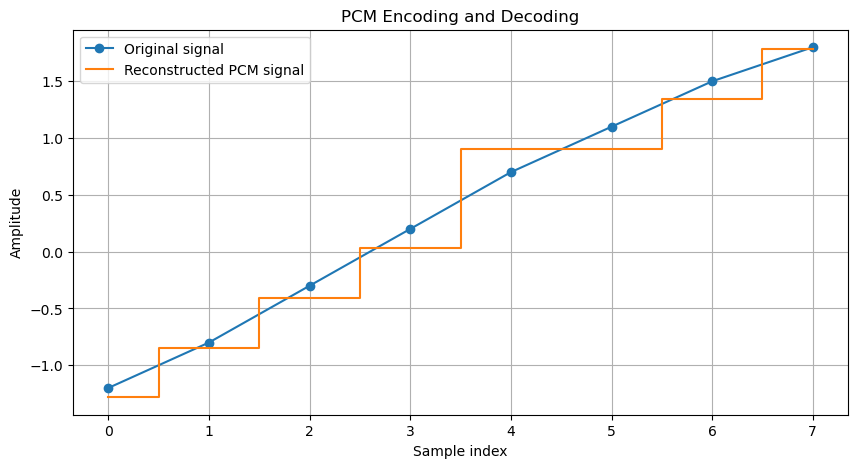

In [39]:
import numpy as np

# Sample analog signal
original_samples = [-1.2, -0.8, -0.3, 0.2, 0.7, 1.1, 1.5, 1.8]

# Encode samples into binary data
binary_data, quantized_values = pcm_encode(original_samples, bits=3)

# Decode the binary data
decoded_values = pcm_decode(binary_data, bits=3)

print("Original samples: ", original_samples)
print("PCM binary data:  ", binary_data)
print("Quantized values: ", quantized_values)
print("Decoded values:   ", decoded_values)
print("Number of samples:", len(decoded_values))

plot_pcm(original_samples, decoded_values)


    DIGITAL SIGNAL ENCODER AND DECODER
1. Generate random binary data
2. Generate data with consecutive zeros
3. Find longest palindromic substring
4. NRZ-L encoding
5. NRZ-I encoding
6. Manchester encoding
7. Differential Manchester encoding
8. AMI encoding
9. B8ZS scrambling
10. HDB3 scrambling
11. PCM encoding and decoding
12. Exit
13. Encode and decode data

Choose line coding scheme:
1. NRZ-L
2. NRZ-I
3. Manchester
4. Differential Manchester
5. AMI

Original data: 10110010
Encoded signal: [1, -1, 1, -1, -1, 1, 1, -1, 1, -1, 1, -1, -1, 1, -1, 1]
Decoded data: 10110010
Successful: True


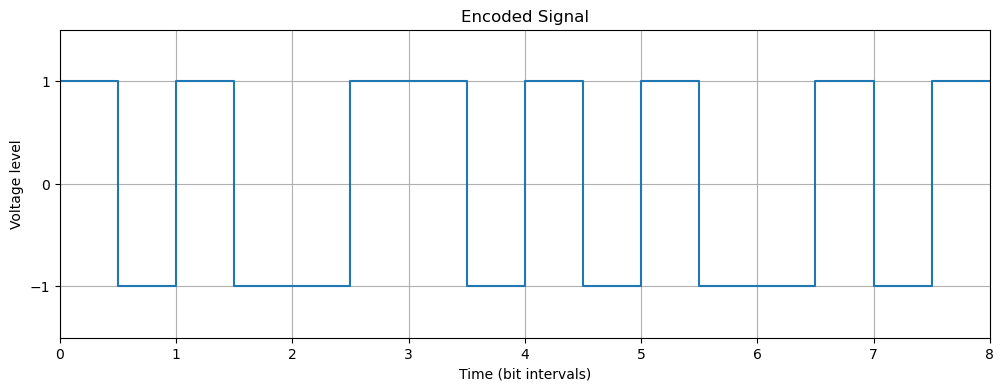


    DIGITAL SIGNAL ENCODER AND DECODER
1. Generate random binary data
2. Generate data with consecutive zeros
3. Find longest palindromic substring
4. NRZ-L encoding
5. NRZ-I encoding
6. Manchester encoding
7. Differential Manchester encoding
8. AMI encoding
9. B8ZS scrambling
10. HDB3 scrambling
11. PCM encoding and decoding
12. Exit
13. Encode and decode data
Exiting program. Goodbye!


In [32]:
def main():
    while True:
        print("\n" + "=" * 50)
        print("    DIGITAL SIGNAL ENCODER AND DECODER")
        print("=" * 50)

        print("1. Generate random binary data")
        print("2. Generate data with consecutive zeros")
        print("3. Find longest palindromic substring")
        print("4. NRZ-L encoding")
        print("5. NRZ-I encoding")
        print("6. Manchester encoding")
        print("7. Differential Manchester encoding")
        print("8. AMI encoding")
        print("9. B8ZS scrambling")
        print("10. HDB3 scrambling")
        print("11. PCM encoding and decoding")
        print("12. Exit")
        print("13. Encode and decode data")

        choice = input("\nEnter your choice: ")

        if choice == "1":
            n = int(input("Enter number of bits: "))
            data = generate_random_data(n)
            print("Generated data:", data)

        elif choice == "2":
            n = int(input("Enter total number of bits: "))
            zero_count = int(input("Enter zero count (4 or 8): "))

            data = generate_data_with_zeros(n, zero_count)
            print("Generated data:", data)

        elif choice == "3":
            data = input("Enter binary data: ")
            result = longest_palindrome(data)
            print("Longest palindrome:", result)
            print("Length:", len(result))

        elif choice in ("4", "5", "6", "7", "8", "9", "10"):
            data = input("Enter binary data: ")

            if choice == "4":
                signal = encode_nrz_l(data)
                title = "NRZ-L Encoding"
                samples_per_bit = 1

            elif choice == "5":
                signal = encode_nrz_i(data)
                title = "NRZ-I Encoding"
                samples_per_bit = 1

            elif choice == "6":
                signal = encode_manchester(data)
                title = "Manchester Encoding"
                samples_per_bit = 2

            elif choice == "7":
                signal = encode_differential_manchester(data)
                title = "Differential Manchester Encoding"
                samples_per_bit = 2

            elif choice == "8":
                signal = encode_ami(data)
                title = "AMI Encoding"
                samples_per_bit = 1

            elif choice == "9":
                signal = encode_b8zs(data)
                title = "B8ZS Encoding"
                samples_per_bit = 1

            else:
                signal = encode_hdb3(data)
                title = "HDB3 Encoding"
                samples_per_bit = 1

            print("Digital data:", data)
            print("Encoded signal:", signal)

            plot_signal(
                data,
                signal,
                title=title,
                samples_per_bit=samples_per_bit
            )

        elif choice == "11":
            samples_input = input(
                "Enter analog sample values separated by spaces: "
            )

            samples = [
                float(value)
                for value in samples_input.split()
            ]

            binary_data, quantized_values = pcm_encode(samples)
            decoded_values = pcm_decode(binary_data)

            print("PCM binary data:", binary_data)
            print("Quantized values:", quantized_values)
            print("Decoded values:", decoded_values)

            plot_pcm(samples, decoded_values)

            answer = input(
                "Encode PCM bitstream using NRZ-L? (yes/no): "
            ).strip().lower()

            if answer == "yes":
                signal = encode_nrz_l(binary_data)
                print("NRZ-L signal:", signal)

                plot_signal(
                    binary_data,
                    signal,
                    title="PCM Output with NRZ-L"
                )

        elif choice == "12":
            print("Exiting program. Goodbye!")
            break


        elif choice == "13":
            data = input("Enter binary data (0s and 1s): ")

            if not data or any(bit not in "01" for bit in data):
                print("Invalid input. Enter a non-empty binary string.")
                continue

            print("\nChoose line coding scheme:")
            print("1. NRZ-L")
            print("2. NRZ-I")
            print("3. Manchester")
            print("4. Differential Manchester")
            print("5. AMI")

            scheme = input("Enter choice: ")

            encoders = {
                "1": (encode_nrz_l, decode_nrz_l),
                "2": (encode_nrz_i, decode_nrz_i),
                "3": (encode_manchester, decode_manchester),
                "4": (encode_differential_manchester, decode_differential_manchester),
                "5": (encode_ami, decode_ami)
            }

            if scheme not in encoders:
                print("Invalid scheme choice.")
                continue

            encoder, decoder = encoders[scheme]

            encoded_signal = encoder(data)
            decoded_data = decoder(encoded_signal)

            print("\nOriginal data:", data)
            print("Encoded signal:", encoded_signal)
            print("Decoded data:", decoded_data)
            print("Successful:", data == decoded_data)

            samples_per_bit = 2 if scheme in ("3", "4") else 1
            plot_signal(data, encoded_signal,
                        title="Encoded Signal",
                        samples_per_bit=samples_per_bit)

                

        else:
            print("Invalid choice. Please try again.")


if __name__ == "__main__":
    main()